In [26]:
import numpy as np
import pandas as pd
import keras
from keras import layers


In [27]:
x_train = pd.read_csv('../data/processed/x_train.csv').to_numpy()
x_val   = pd.read_csv('../data/processed/x_val.csv').to_numpy()
y_train = pd.read_csv('../data/processed/y_train.csv').to_numpy()
y_val   = pd.read_csv('../data/processed/y_val.csv').to_numpy()

In [28]:
n_features = x_train.shape[1]            
x_train = x_train.reshape(-1, 1, n_features)
x_val   = x_val.reshape(-1, 1, n_features)
print(x_train.shape, x_val.shape) 

(16138, 1, 17) (4493, 1, 17)


In [29]:
keras.backend.clear_session()
inp = layers.Input(shape=(1, n_features))
x = layers.GRU(64, return_sequences=True)(inp)
x = layers.GRU(32)(x)
x = layers.Dropout(0.2)(x)
out = layers.Dense(1)(x)
model = keras.Model(inp, out)
model.compile(optimizer='adam', loss='mse', metrics=['mae', 'mse'])
model.summary()

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath='../models/gru_model.keras',
        save_best_only=True,
        monitor='val_loss',
    )
]

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1, 17)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 1, 64)          │        15,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,377 (99.13 KB)

 Trainable params: 25,377 (99.13 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 12435.5654 - mae: 91.0781 - mse: 12435.5654 - val_loss: 15060.5264 - val_mae: 97.9099 - val_mse: 15060.5264
Epoch 2/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 9635.0996 - mae: 77.9079 - mse: 9635.0996 - val_loss: 12429.8691 - val_mae: 87.2275 - val_mse: 12429.8691
Epoch 3/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 7782.8569 - mae: 69.3580 - mse: 7782.8569 - val_loss: 10464.7207 - val_mae: 79.3954 - val_mse: 10464.7207
Epoch 4/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 6487.3813 - mae: 63.4112 - mse: 6487.3813 - val_loss: 9025.5244 - val_mae: 73.7988 - val_mse: 9025.5244
Epoch 5/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5593.8438 - mae: 59.4000 - mse: 5593.8438 - val_loss: 8001.4165 - val_mae: 69.9433 - val_mse: 8001.4165
Epoch 6/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5033.3530 - mae: 57.1042 - mse: 5033.3530 - val_loss: 7294.4346 - val_mae: 67.3974 - val_mse: 7294.4346
Ep

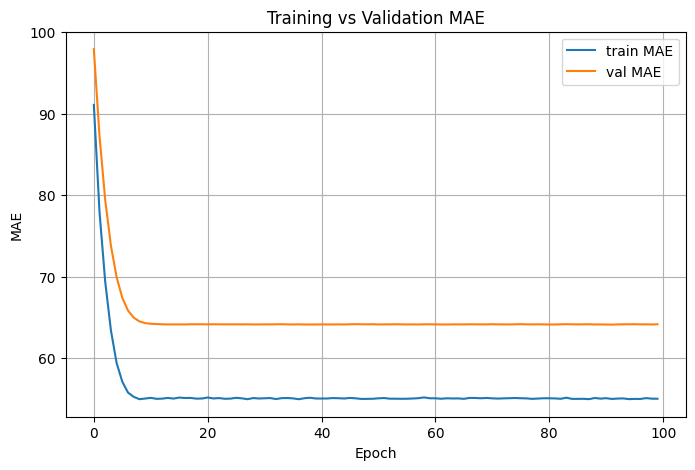

In [31]:
# elbow method
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history["mae"], label="train MAE")
plt.plot(history.history["val_mae"], label="val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

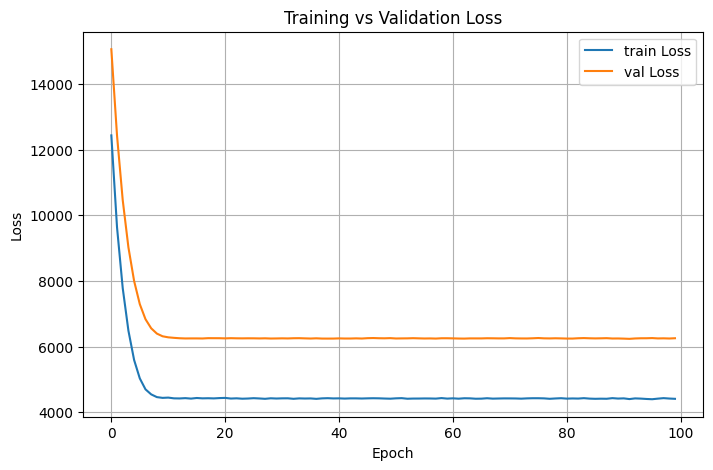

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="train Loss")
plt.plot(history.history["val_loss"], label="val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
model = keras.models.load_model("../models/gru_model.keras")
model.evaluate(x_val , y_val)
print(f"Model evaluation on validation set: Loss = {model.evaluate(x_val , y_val)[0]}, MAE = {model.evaluate(x_val , y_val)[1]}")

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6237.9707 - mae: 64.1083 - mse: 6237.9707
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6237.9707 - mae: 64.1083 - mse: 6237.9707
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6237.9707 - mae: 64.1083 - mse: 6237.9707
Model evaluation on validation set: Loss = 6237.970703125, MAE = 64.10832977294922
